# Projet 1 (CS-433) — Data preprocessing

This notebook prepares the data x_train and y_train, and it produces **2 preprocessed versions** :

| Version | Use `y` ? | What it does |
|---|---|---|
| **v1 — X only** | no | cleanup, special blocks, NaN, outliers, normalisation, redundant columns |
| **v2 — X + y** | yes | same as v1, **plus** selection of features based on correlation with the target |

I only used the standard library, numpy and matplotlib/seaborn to respect the project guidelines

I print and save the generated figures on the repository


# **HOW TO USE**

The preprocessing has already been run, so you normally do not need to rerun this notebook.
Ready-to-use datasets are available in data/processed/

## **Which file should I use?**

train_v1_X_only.npz → recommended default

train_v2_X_y.npz → same dataset with additional target-based feature selection

train_v2_X_y_balanced.npz → balanced version for quick experiments only

test_v1_X_only.npz / test_v2_X_y.npz → matching test sets for final predictions

## **Always use matching train/test versions:**

train_v1_X_only.npz  <->  test_v1_X_only.npz
train_v2_X_y.npz     <->  test_v2_X_y.npz

## **Loading the data**

import numpy as np

### Training data
d = np.load("data/processed/train_v1_X_only.npz")

x = d["x"]
y = d["y"]
ids = d["ids"]
feature_names = d["feature_names"]

### Add bias column expected by the project functions
tx = np.c_[np.ones(len(x)), x]

### Matching test data
t = np.load("data/processed/test_v1_X_only.npz")

x_test = t["x"]
ids_test = t["ids"]
tx_test = np.c_[np.ones(len(x_test)), x_test]

## **Important conventions**

y is encoded as {0, 1} for training.

AIcrowd submissions require predictions in {-1, +1}:

y_pred_submission = 2 * y_pred - 1

Features are already imputed and standardized.

There are no remaining NaN values.

Arrays are stored as float32; convert to float64 if needed:

x = x.astype(np.float64)

For most experiments, start with train_v1_X_only.npz.
The balanced dataset should only be used for quick training experiments, not for validation or evaluation.

## Imports and parameters

In [1]:
import json
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

SEED = 42                      # for reproducibility

NAN_COL_MAX     = 0.50         # delete col with more than 50% of Nan
CAT_MAX_UNIQUE  = 15           # <= 15 distinct values -> discrete variable otherwise continuous
CLIP_QUANTILES  = (0.005, 0.995)  # limits outliers
CORR_X_MAX      = 0.95         # if |corr| > 0.95 between two cols, keep only the first

# --- v2 only (use y_train) ---
CORR_Y_MIN      = 0.01         # keep features with |corr(feature, y)| >= 0.01
BALANCE_RATIO   = 1.0          

# --- options ---
SAVE_CSV        = False        # True : exports also .csv
PROCESS_TEST    = True         # True : transforme also x_test.csv if present in data/

# graphics style
BLUE, ORANGE, GREY = "#2f6db5", "#d9822b", "#8a8f98"
sns.set_theme(style="whitegrid", rc={"axes.spines.top": False, "axes.spines.right": False,
                                     "axes.edgecolor": GREY, "grid.color": "#e6e8eb", "figure.dpi": 110})
rng = np.random.default_rng(SEED)

## Loading data

In [2]:
def find_project_root(start=None):
    start = Path(start or Path.cwd()).resolve()
    for p in [start, *start.parents]:
        if (p / "data" / "x_train.csv").exists():
            return p
    raise FileNotFoundError("data/x_train.csv introuvable : ouvre le notebook depuis le dossier du projet (projects/project1).")


def load_csv_fast(path, chunk_lines=20000):
    """Loads csv with col labels -> (column names, float64 array). Empty fields -> NaN."""
    parts = []
    with open(path) as f:
        header = f.readline().strip().split(",")
        n = len(header)
        while True:
            lines = [l for _, l in zip(range(chunk_lines), f)]
            if not lines:
                break
            txt = "".join(lines).replace("\r", "")
            txt = txt.replace(",,", ",nan,").replace(",,", ",nan,").replace(",\n", ",nan\n").replace("\n,", "\nnan,")
            tokens = txt.replace("\n", ",").rstrip(",").split(",")
            parts.append(np.array(tokens, dtype=np.float64).reshape(-1, n))
    return header, np.vstack(parts)


ROOT = find_project_root()
DATA = ROOT / "data"
OUT = DATA / "processed"
OUT.mkdir(exist_ok=True)

# where figures go after being saves
FIG_DIR = ROOT / "figures" / "preprocessing"
FIG_DIR.mkdir(parents=True, exist_ok=True)


def save_fig(name):
    """Saves fig for overleaf pdf"""
    for ext in ("pdf", "png"):
        plt.savefig(FIG_DIR / f"{name}.{ext}", dpi=300, bbox_inches="tight")
    print(f"figure sauvegardée : {(FIG_DIR / name).relative_to(ROOT)}.pdf / .png")


print("Racine du projet :", ROOT)

t0 = time.time()
names, X_raw = load_csv_fast(DATA / "x_train.csv")
y_names, Y_raw = load_csv_fast(DATA / "y_train.csv")
print(f"x_train : {X_raw.shape}   y_train : {Y_raw.shape}   ({time.time()-t0:.0f} s)")


assert names[0] == "Id" and y_names == ["Id", "_MICHD"]
assert np.array_equal(X_raw[:, 0], Y_raw[:, 0]), "Les Id de x_train et y_train ne sont pas alignés !"
ids = X_raw[:, 0].astype(np.int64)
y_pm1 = Y_raw[:, 1]                       # étiquettes originales : -1 / +1
assert set(np.unique(y_pm1)) == {-1.0, 1.0}
y = (y_pm1 == 1).astype(np.int8)          # étiquettes en {0, 1} (requis par la régression logistique du projet)
print("Étiquettes converties de {-1, +1} vers {0, 1}.")

Racine du projet : C:\Users\Anwender\Desktop\cs433-projects\projects\project1
x_train : (328135, 322)   y_train : (328135, 2)   (38 s)
Étiquettes converties de {-1, +1} vers {0, 1}.


## Raw data

328135 individus, 321 features. Positifs (MICHD=1) : 28975 (8.8%), négatifs : 299160 (91.2%)
figure sauvegardée : figures\preprocessing\01_class_balance.pdf / .png


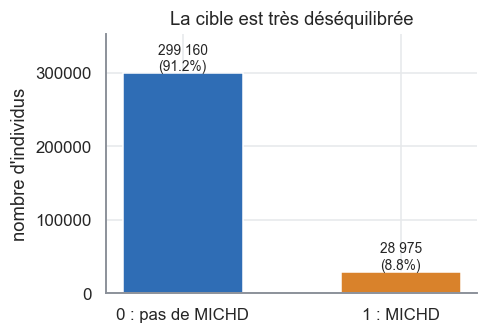

In [3]:
n, d = X_raw.shape[0], X_raw.shape[1] - 1
n_pos = int(y.sum()); n_neg = n - n_pos
print(f"{n} individus, {d} features. Positifs (MICHD=1) : {n_pos} ({n_pos/n:.1%}), négatifs : {n_neg} ({n_neg/n:.1%})")

fig, ax = plt.subplots(figsize=(4.6, 3.2))
bars = ax.bar(["0 : pas de MICHD", "1 : MICHD"], [n_neg, n_pos], color=[BLUE, ORANGE], width=0.55)
for b, v in zip(bars, [n_neg, n_pos]):
    ax.text(b.get_x() + b.get_width()/2, v, f"{v:,}\n({v/n:.1%})".replace(",", " "), ha="center", va="bottom", fontsize=9)
ax.set_ylim(0, n_neg * 1.18); ax.set_ylabel("nombre d'individus"); ax.set_title("La cible est très déséquilibrée")
plt.tight_layout(); save_fig("01_class_balance"); plt.show()

Lignes contenant au moins un NaN : 100.0%   <- retirer ces lignes viderait tout le dataset !
Colonnes avec >50% de NaN : 147 sur 321   |   sans aucun NaN : 82
figure sauvegardée : figures\preprocessing\02_missing_values.pdf / .png


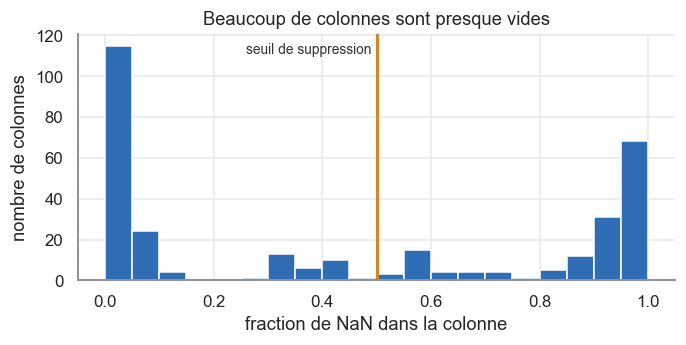

In [4]:
nan_frac = np.isnan(X_raw[:, 1:]).mean(axis=0)
rows_with_nan = np.isnan(X_raw[:, 1:]).any(axis=1).mean()
print(f"Lignes contenant au moins un NaN : {rows_with_nan:.1%}   <- retirer ces lignes viderait tout le dataset !")
print(f"Colonnes avec >{NAN_COL_MAX:.0%} de NaN : {(nan_frac > NAN_COL_MAX).sum()} sur {d}   |   sans aucun NaN : {(nan_frac == 0).sum()}")

fig, ax = plt.subplots(figsize=(6.4, 3.3))
ax.hist(nan_frac, bins=20, color=BLUE, edgecolor="white")
ax.axvline(NAN_COL_MAX, color=ORANGE, lw=2)
ax.text(NAN_COL_MAX - 0.01, ax.get_ylim()[1] * 0.92, "seuil de suppression", color="#333", ha="right", fontsize=9)
ax.set_xlabel("fraction de NaN dans la colonne"); ax.set_ylabel("nombre de colonnes")
ax.set_title("Beaucoup de colonnes sont presque vides"); plt.tight_layout(); save_fig("02_missing_values"); plt.show()

## Duplicates

In [5]:
def duplicate_row_mask(A):
    """True for each line that is a duplicate of a previous line (keep 1st occurence)"""
    A = np.ascontiguousarray(A)
    rows = A.view(np.dtype((np.void, A.dtype.itemsize * A.shape[1]))).ravel()
    _, first = np.unique(rows, return_index=True)
    mask = np.ones(len(A), dtype=bool)
    mask[first] = False
    return mask


dup = duplicate_row_mask(X_raw[:, 1:])
print(f"Lignes dupliquées : {dup.sum()}")
if dup.any():
    X_raw, y, ids = X_raw[~dup], y[~dup], ids[~dup]
    print(f"Doublons retirés -> {len(X_raw)} lignes restantes")

Lignes dupliquées : 0


## Cols to remove because special code BRFSS

**Some cols aren't real features**
- identifiers, dates etc.(`SEQNO`, `_PSU`, `IDATE`, …) and nominal codes without order (`_STATE`, `EXRACT11`, `EXRACT21`)
- cols « raw » mixing multiple units (ex. `ALCDAY5` : 1xx = days per week, 2xx = days per month ; `WEIGHT2` : pounds or kg). Keep only the variables that summarize these values (`_DRNKWEK`, `WTKG3`, `HTM4`, `FTJUDA1_`, …)

**Special BRFSS code** : `7`/`9` (don't know / refuse), `77`/`99`, `777`/`999`… and `88`

In [6]:
# discarded cols
DROP_ADMIN = ["IDATE", "SEQNO", "_PSU", "IMONTH", "IDAY", "IYEAR", "FMONTH", "DISPCODE", "QSTVER", "_STSTR",
              "_STATE", "EXRACT11", "EXRACT21"]
DROP_MIXED_UNITS = ["WEIGHT2", "HEIGHT3", "ALCDAY5", "FRUITJU1", "FRUIT1", "FVBEANS", "FVGREEN", "FVORANG", "VEGETAB1",
                    "EXEROFT1", "EXEROFT2", "EXERHMM1", "EXERHMM2", "STRENGTH", "BLDSUGAR", "FEETCHK2", "LONGWTCH",
                    "FLSHTMY2", "HIVTSTD3", "ASACTLIM"]

# replace specific codes "nan" = refuse / don't know,  "zero" = "none" (remplace with 0)
EXPLICIT_CODES = {
    "PHYSHLTH": {"zero": [88], "nan": [77, 99]},
    "MENTHLTH": {"zero": [88], "nan": [77, 99]},
    "POORHLTH": {"zero": [88], "nan": [77, 99]},
    "CHILDREN": {"zero": [88], "nan": [99]},
    "HHADULT":  {"nan": [77, 99]},
    "DIABAGE2": {"nan": [77, 99]},
    "DRNK3GE5": {"zero": [88], "nan": [77, 99]},
    "AVEDRNK2": {"nan": [77, 99]},
    "MAXDRNKS": {"nan": [77, 99]},
    "DOCTDIAB": {"zero": [88], "nan": [77, 99]},
    "CHKHEMO3": {"zero": [88], "nan": [77, 99]},
    "FEETCHK":  {"zero": [88], "nan": [77, 99]},
    "DROCDY3_": {"nan": [900]},
    "_DRNKWEK": {"nan": [99900]},
    "MAXVO2_":  {"nan": [999]},
    "FC60_":    {"nan": [999]},
}

missing_in_header = [c for c in DROP_ADMIN + DROP_MIXED_UNITS + list(EXPLICIT_CODES) if c not in names]
print("Colonnes de ces listes absentes du fichier :", missing_in_header or "aucune")


def detect_codes(name, col, cat_max_unique):
    """Renvoie (codes_nan, codes_zero) pour une colonne."""
    if name in EXPLICIT_CODES:
        e = EXPLICIT_CODES[name]
        return list(e.get("nan", [])), list(e.get("zero", []))
    u = np.unique(col[~np.isnan(col)])
    if u.size == 0 or u.size > cat_max_unique or not np.all(u == np.round(u)):
        return [], []
    codes = []
    if u.max() <= 9:
        run = 0                                   # plus grand k tel que 1..k sont tous présents (échelle "normale")
        while (run + 1) in u:
            run += 1
        codes = [int(v) for v in u if v in (7, 9) and v > run]
        if u.max() == 9 and 9 not in codes:       # 9 = "refuse" même quand l'échelle 1..9 est complète
            codes.append(9)
    elif 77 in u or 99 in u:
        codes = [int(v) for v in (77, 99) if v in u]
    return sorted(codes), []


def apply_codes(col, nan_codes, zero_codes):
    c = col.astype(np.float64, copy=True)
    if zero_codes:
        c[np.isin(c, zero_codes)] = 0.0
    if nan_codes:
        c[np.isin(c, nan_codes)] = np.nan
    return c

Colonnes de ces listes absentes du fichier : aucune


## Preprocessor

For each remaining col `fit_preprocessor`does in this order:

1. special codes → NaN (or 0 for "none")
2. deletion if too many NaN or if the col is constant
3. outliers : for continuous variables → *winsoriation* to quantiles `CLIP_QUANTILES`
4. imputation of NaN
5. normalisation (*z-score*) → good for methods with gradient descent!
6. deletion of redundant cols

`transform` reapplies these steps with the saved params at the beginning of the notebook -> we will use this on x_test

In [7]:
def transform(X, header, params):
    """Applique un préprocesseur déjà ajusté (params) à un tableau brut X -> matrice float32 normalisée."""
    idx = {nm: i for i, nm in enumerate(header)}
    Z = np.empty((X.shape[0], len(params["columns"])), dtype=np.float32)
    for k, p in enumerate(params["columns"]):
        c = apply_codes(X[:, idx[p["name"]]], p["nan_codes"], p["zero_codes"])
        c = np.clip(c, p["lo"], p["hi"])                       # les NaN restent NaN
        c = np.where(np.isnan(c), p["fill"], c)
        Z[:, k] = (c - p["mean"]) / p["std"]
    return Z


def fit_preprocessor(X, header, cfg):
    """Calcule tous les paramètres du pré-traitement sur X (train). Renvoie un dict sérialisable en JSON."""
    n = X.shape[0]
    reasons, cols, Zparts = {}, [], []
    def drop(reason, name): reasons.setdefault(reason, []).append(name)

    for j, name in enumerate(header):
        if name == "Id":
            continue
        if name in DROP_ADMIN:
            drop("administratif / code nominal non ordonné", name); continue
        if name in DROP_MIXED_UNITS:
            drop("unités mélangées (remplacé par une variable dérivée)", name); continue
        nan_codes, zero_codes = detect_codes(name, X[:, j], cfg["cat_max_unique"])
        c = apply_codes(X[:, j], nan_codes, zero_codes)
        if np.isnan(c).mean() > cfg["nan_col_max"]:
            drop(f"plus de {cfg['nan_col_max']:.0%} de NaN", name); continue
        obs = c[~np.isnan(c)]
        n_unique = np.unique(obs).size
        if n_unique <= 1:
            drop("constante", name); continue
        kind = "cont" if n_unique > cfg["cat_max_unique"] else "cat"
        if kind == "cont":
            lo, hi = (float(v) for v in np.quantile(obs, cfg["clip_quantiles"]))
        else:
            lo, hi = float(obs.min()), float(obs.max())
        obs = np.clip(obs, lo, hi)
        if kind == "cont":
            fill = float(np.median(obs))
        else:
            vals, counts = np.unique(obs, return_counts=True)
            fill = float(vals[np.argmax(counts)])
        c = np.where(np.isnan(np.clip(c, lo, hi)), fill, np.clip(c, lo, hi))
        std = float(c.std())
        if std < 1e-8:
            drop("variance nulle après nettoyage", name); continue
        mean = float(c.mean())
        Zparts.append(((c - mean) / std).astype(np.float32))
        cols.append(dict(name=name, kind=kind, nan_codes=nan_codes, zero_codes=zero_codes,
                         lo=lo, hi=hi, fill=fill, mean=mean, std=std))

    # Colonnes redondantes : après normalisation, corr(i, j) = (Z_i . Z_j) / n
    Z = np.column_stack(Zparts)
    C = (Z.T @ Z) / n
    keep = np.ones(len(cols), dtype=bool)
    for j in range(1, len(cols)):
        prev = np.where(keep[:j])[0]
        r = np.abs(C[prev, j])
        if r.max() > cfg["corr_x_max"]:
            keep[j] = False
            drop(f"corrélée à plus de {cfg['corr_x_max']} avec une colonne déjà gardée",
                 f"{cols[j]['name']} (~ {cols[prev[r.argmax()]]['name']})")
    params = dict(config=cfg, columns=[c for c, k in zip(cols, keep) if k], dropped=reasons)
    return params, Z[:, keep]


cfg = dict(nan_col_max=NAN_COL_MAX, cat_max_unique=CAT_MAX_UNIQUE, clip_quantiles=list(CLIP_QUANTILES), corr_x_max=CORR_X_MAX)
t0 = time.time()
params_v1, Z_fit = fit_preprocessor(X_raw, names, cfg)
Z = transform(X_raw, names, params_v1)
assert np.allclose(Z, Z_fit, atol=1e-5), "fit et transform ne donnent pas le même résultat !"
feature_names = np.array([c["name"] for c in params_v1["columns"]])
print(f"Terminé en {time.time()-t0:.0f} s  ->  Z : {Z.shape}")

Terminé en 15 s  ->  Z : (328135, 124)


## What has been deleted

In [8]:
print(f"Colonnes de départ : {d}   ->   colonnes gardées : {Z.shape[1]}\n")
for reason, lst in params_v1["dropped"].items():
    print(f"- {len(lst):3d} colonnes : {reason}")
    if len(lst) <= 12:
        print("      ", ", ".join(lst))

from collections import defaultdict
groups = defaultdict(list)
for c in params_v1["columns"]:
    if c["nan_codes"] or c["zero_codes"]:
        groups[(tuple(c["nan_codes"]), tuple(c["zero_codes"]))].append(c["name"])
print(f"\nColonnes gardées avec codes spéciaux traités : {sum(map(len, groups.values()))}  (à vérifier avec le codebook)")
for (a, b), lst in sorted(groups.items(), key=lambda kv: -len(kv[1])):
    print(f"\n  NaN pour {list(a) or '-'}" + (f", 0 pour {list(b)}" if b else "") + f"  ({len(lst)} colonnes) :")
    print("    " + ", ".join(lst))
n_cont = sum(c["kind"] == "cont" for c in params_v1["columns"])
print(f"\nTypes des colonnes gardées : {n_cont} continues, {Z.shape[1]-n_cont} catégorielles / discrètes")

Colonnes de départ : 321   ->   colonnes gardées : 124

-  13 colonnes : administratif / code nominal non ordonné
-   2 colonnes : constante
       CTELENUM, STATERES
- 140 colonnes : plus de 50% de NaN
-  20 colonnes : unités mélangées (remplacé par une variable dérivée)
-  22 colonnes : corrélée à plus de 0.95 avec une colonne déjà gardée

Colonnes gardées avec codes spéciaux traités : 77  (à vérifier avec le codebook)

  NaN pour [7, 9]  (38 colonnes) :
    GENHLTH, HLTHPLN1, PERSDOC2, MEDCOST, CHECKUP1, BPHIGH4, BLOODCHO, CHOLCHK, TOLDHI2, CVDSTRK3, ASTHMA3, CHCSCNCR, CHCOCNCR, CHCCOPD1, HAVARTH3, ADDEPEV2, CHCKIDNY, DIABETE3, RENTHOM1, NUMHHOL2, CPDEMO1, VETERAN3, INTERNET, QLACTLM2, USEEQUIP, BLIND, DECIDE, DIFFWALK, DIFFDRES, DIFFALON, SMOKE100, USENOW3, EXERANY2, SEATBELT, FLUSHOT6, PNEUVAC3, HIVTST6, DRNKANY5

  NaN pour [9]  (30 colonnes) :
    MARITAL, EDUCA, EMPLOY1, _DUALUSE, _RFHLTH, _CASTHM1, _ASTHMS1, _HISPANC, _RACE, _RACEG21, _RFBMI5, _SMOKER3, _RFSMOK3, _RFBING5, _RF

## Quality control

In [9]:
assert not np.isnan(Z).any() and not np.isinf(Z).any(), "NaN ou inf restants"
assert np.allclose(Z.mean(axis=0, dtype=np.float64), 0, atol=1e-3) and np.allclose(Z.std(axis=0, dtype=np.float64), 1, atol=1e-3), "normalisation incorrecte"
assert Z.shape[0] == len(y) == len(ids)
print("OK : plus aucun NaN/inf, moyenne 0 et écart-type 1 pour chaque colonne, dimensions cohérentes.")

OK : plus aucun NaN/inf, moyenne 0 et écart-type 1 pour chaque colonne, dimensions cohérentes.


## Before/after on a couple of variables

figure sauvegardée : figures\preprocessing\03_before_after.pdf / .png


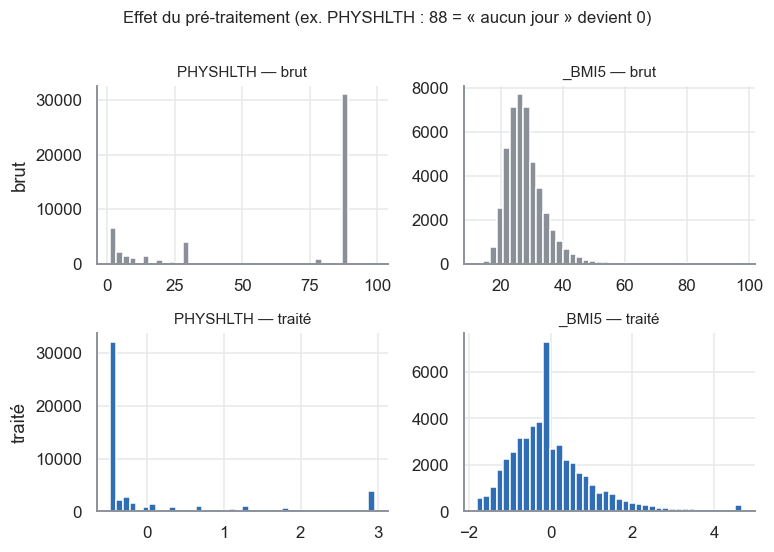

In [10]:
demo = [f for f in ["PHYSHLTH", "_BMI5", "_AGE80"] if f in feature_names]
sample = rng.choice(len(X_raw), size=50_000, replace=False)
col_of = {nm: i for i, nm in enumerate(names)}
fig, axes = plt.subplots(2, len(demo), figsize=(3.6 * len(demo), 5), squeeze=False)
for k, f in enumerate(demo):
    raw = X_raw[sample, col_of[f]]; raw = raw[~np.isnan(raw)]
    axes[0, k].hist(raw, bins=40, color=GREY, edgecolor="white")
    axes[0, k].set_title(f"{f} — brut", fontsize=10)
    axes[1, k].hist(Z[sample, list(feature_names).index(f)], bins=40, color=BLUE, edgecolor="white")
    axes[1, k].set_title(f"{f} — traité", fontsize=10)
axes[0, 0].set_ylabel("brut"); axes[1, 0].set_ylabel("traité")
fig.suptitle("Effet du pré-traitement (ex. PHYSHLTH : 88 = « aucun jour » devient 0)", y=1.0, fontsize=11)
plt.tight_layout(); save_fig("03_before_after"); plt.show()

## Saving version 1 (x_train alone)

In [11]:
def save_npz(path, **arrays):
    np.savez(path, **arrays)
    print(f"  -> {path.relative_to(ROOT)}  ({path.stat().st_size/1e6:.0f} Mo)")


def save_params(path, params, **extra):
    with open(path, "w") as f:
        json.dump({**params, **extra}, f, indent=1)
    print(f"  -> {path.relative_to(ROOT)}")


def save_csv(path, x, y, ids, feature_names):
    """Export CSV optionnel : Id, _MICHD, puis les features (lent : ~1-2 min)."""
    M = np.column_stack([ids, y, x])
    np.savetxt(path, M, delimiter=",", header=",".join(["Id", "_MICHD", *feature_names]), comments="", fmt="%.6g")
    print(f"  -> {path.relative_to(ROOT)}")


print("Version 1 (X seul) :")
save_npz(OUT / "train_v1_X_only.npz", x=Z, y=y, ids=ids, feature_names=feature_names)
save_params(OUT / "preprocess_params_v1.json", params_v1)
if SAVE_CSV:
    save_csv(OUT / "train_v1_X_only.csv", Z, y, ids, feature_names)

Version 1 (X seul) :
  -> data\processed\train_v1_X_only.npz  (166 Mo)
  -> data\processed\preprocess_params_v1.json


## Saving version 2 (preprocessing on x_train **and** y_train)

figure sauvegardée : figures\preprocessing\04_target_correlation.pdf / .png


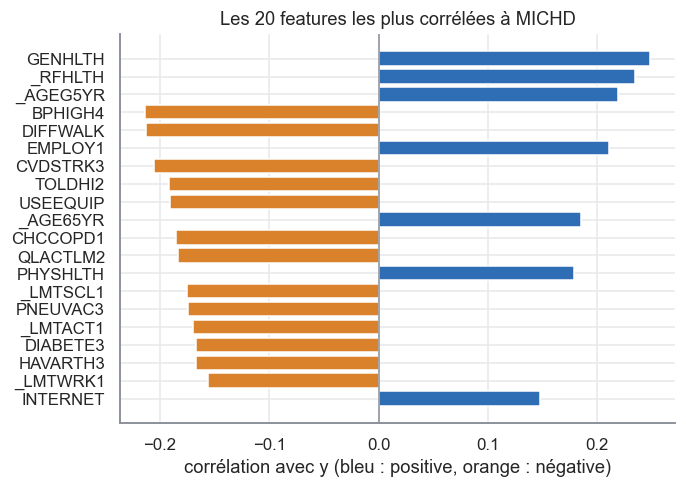

Attention : le signe dépend du codage BRFSS (ex. pour beaucoup de questions 1 = oui, 2 = non, donc une corrélation négative signifie « répondre oui va avec MICHD = 1 »). Seule la valeur absolue compte pour la sélection.
Features avec |corr| >= 0.01 : 110 sur 124


In [12]:
def target_correlation(Z, y):
    """Corrélation de Pearson entre chaque colonne (déjà normalisée, moyenne 0 / écart-type 1) et y."""
    yc = y - y.mean()
    return (Z.T @ yc) / (len(y) * y.std())


def select_by_target_corr(Z, y, threshold):
    """Indices des colonnes avec |corr(colonne, y)| >= threshold."""
    return np.where(np.abs(target_correlation(Z, y)) >= threshold)[0]


def undersample_majority(y, ratio, rng):
    """Indices (mélangés) gardant tous les positifs et ratio x n_pos négatifs tirés au hasard."""
    pos = np.where(y == 1)[0]
    neg = np.where(y == 0)[0]
    neg = rng.choice(neg, size=min(len(neg), int(ratio * len(pos))), replace=False)
    idx = np.concatenate([pos, neg])
    rng.shuffle(idx)
    return idx


r = target_correlation(Z, y)
order = np.argsort(-np.abs(r))
fig, ax = plt.subplots(figsize=(6.4, 4.6))
top = order[:20][::-1]
ax.barh(feature_names[top], r[top], color=[BLUE if v > 0 else ORANGE for v in r[top]])
ax.axvline(0, color=GREY, lw=1)
ax.set_xlabel("corrélation avec y (bleu : positive, orange : négative)")
ax.set_title("Les 20 features les plus corrélées à MICHD"); plt.tight_layout(); save_fig("04_target_correlation"); plt.show()
print("Attention : le signe dépend du codage BRFSS (ex. pour beaucoup de questions 1 = oui, 2 = non, donc une corrélation négative "
      "signifie « répondre oui va avec MICHD = 1 »). Seule la valeur absolue compte pour la sélection.")

sel = select_by_target_corr(Z, y, CORR_Y_MIN)
print(f"Features avec |corr| >= {CORR_Y_MIN} : {len(sel)} sur {Z.shape[1]}")

figure sauvegardée : figures\preprocessing\05_correlation_heatmap.pdf / .png


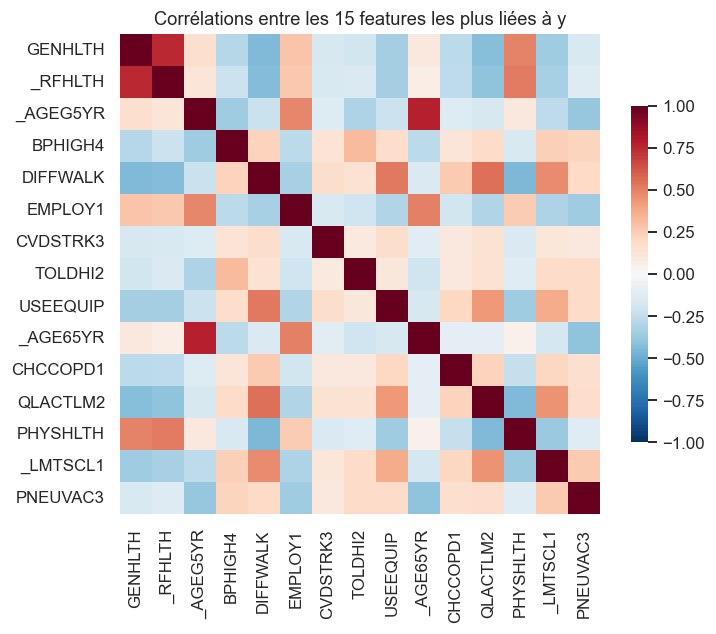

In [13]:
# Heatmap des 15 features les plus corrélées à y (pour repérer d'éventuelles redondances restantes)
top15 = order[:15]
Cm = np.corrcoef(Z[:, top15].T)
fig, ax = plt.subplots(figsize=(7, 5.8))
sns.heatmap(Cm, xticklabels=feature_names[top15], yticklabels=feature_names[top15], cmap="RdBu_r",
            center=0, vmin=-1, vmax=1, square=True, cbar_kws={"shrink": 0.7}, ax=ax)
ax.set_title("Corrélations entre les 15 features les plus liées à y"); plt.tight_layout(); save_fig("05_correlation_heatmap"); plt.show()

In [14]:
# Application : v2 = mêmes paramètres que v1, restreints aux features sélectionnées
params_v2 = dict(params_v1, columns=[params_v1["columns"][i] for i in sel])
Z2 = Z[:, sel]
feature_names_v2 = feature_names[sel]

bal_idx = undersample_majority(y, BALANCE_RATIO, rng)
Z2_bal, y_bal, ids_bal = Z2[bal_idx], y[bal_idx], ids[bal_idx]
print(f"v2 (toutes les lignes) : {Z2.shape}   |   v2 rééquilibrée : {Z2_bal.shape}, positifs = {y_bal.mean():.1%}")

print("Version 2 (X + y) :")
save_npz(OUT / "train_v2_X_y.npz", x=Z2, y=y, ids=ids, feature_names=feature_names_v2)
save_npz(OUT / "train_v2_X_y_balanced.npz", x=Z2_bal, y=y_bal, ids=ids_bal, feature_names=feature_names_v2)
save_params(OUT / "preprocess_params_v2.json", params_v2,
            target_corr_threshold=CORR_Y_MIN, balance_ratio=BALANCE_RATIO, seed=SEED)
if SAVE_CSV:
    save_csv(OUT / "train_v2_X_y.csv", Z2, y, ids, feature_names_v2)
    save_csv(OUT / "train_v2_X_y_balanced.csv", Z2_bal, y_bal, ids_bal, feature_names_v2)

v2 (toutes les lignes) : (328135, 110)   |   v2 rééquilibrée : (57950, 110), positifs = 50.0%
Version 2 (X + y) :
  -> data\processed\train_v2_X_y.npz  (147 Mo)
  -> data\processed\train_v2_X_y_balanced.npz  (26 Mo)
  -> data\processed\preprocess_params_v2.json


## Apply same preprocessing to x_test

In [15]:
test_path = DATA / "x_test.csv"
if PROCESS_TEST and test_path.exists():
    test_names, X_test_raw = load_csv_fast(test_path)
    assert test_names == names, "Les colonnes de x_test ne correspondent pas à celles de x_train"
    ids_test = X_test_raw[:, 0].astype(np.int64)
    Zt1 = transform(X_test_raw, test_names, params_v1)
    Zt2 = transform(X_test_raw, test_names, params_v2)
    assert not np.isnan(Zt1).any() and not np.isnan(Zt2).any()
    print("Test :")
    save_npz(OUT / "test_v1_X_only.npz", x=Zt1, ids=ids_test, feature_names=feature_names)
    save_npz(OUT / "test_v2_X_y.npz", x=Zt2, ids=ids_test, feature_names=feature_names_v2)
else:
    print("x_test.csv absent de data/ (ou PROCESS_TEST=False) : étape ignorée. Relance ce notebook quand il sera ajouté.")

Test :
  -> data\processed\test_v1_X_only.npz  (55 Mo)
  -> data\processed\test_v2_X_y.npz  (49 Mo)
